<a href="https://colab.research.google.com/github/OJB-Quantum/QC-Hardware-How-To/blob/main/Jupyter%20Notebook%20Scripts/Qubit_Classification_Tree_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

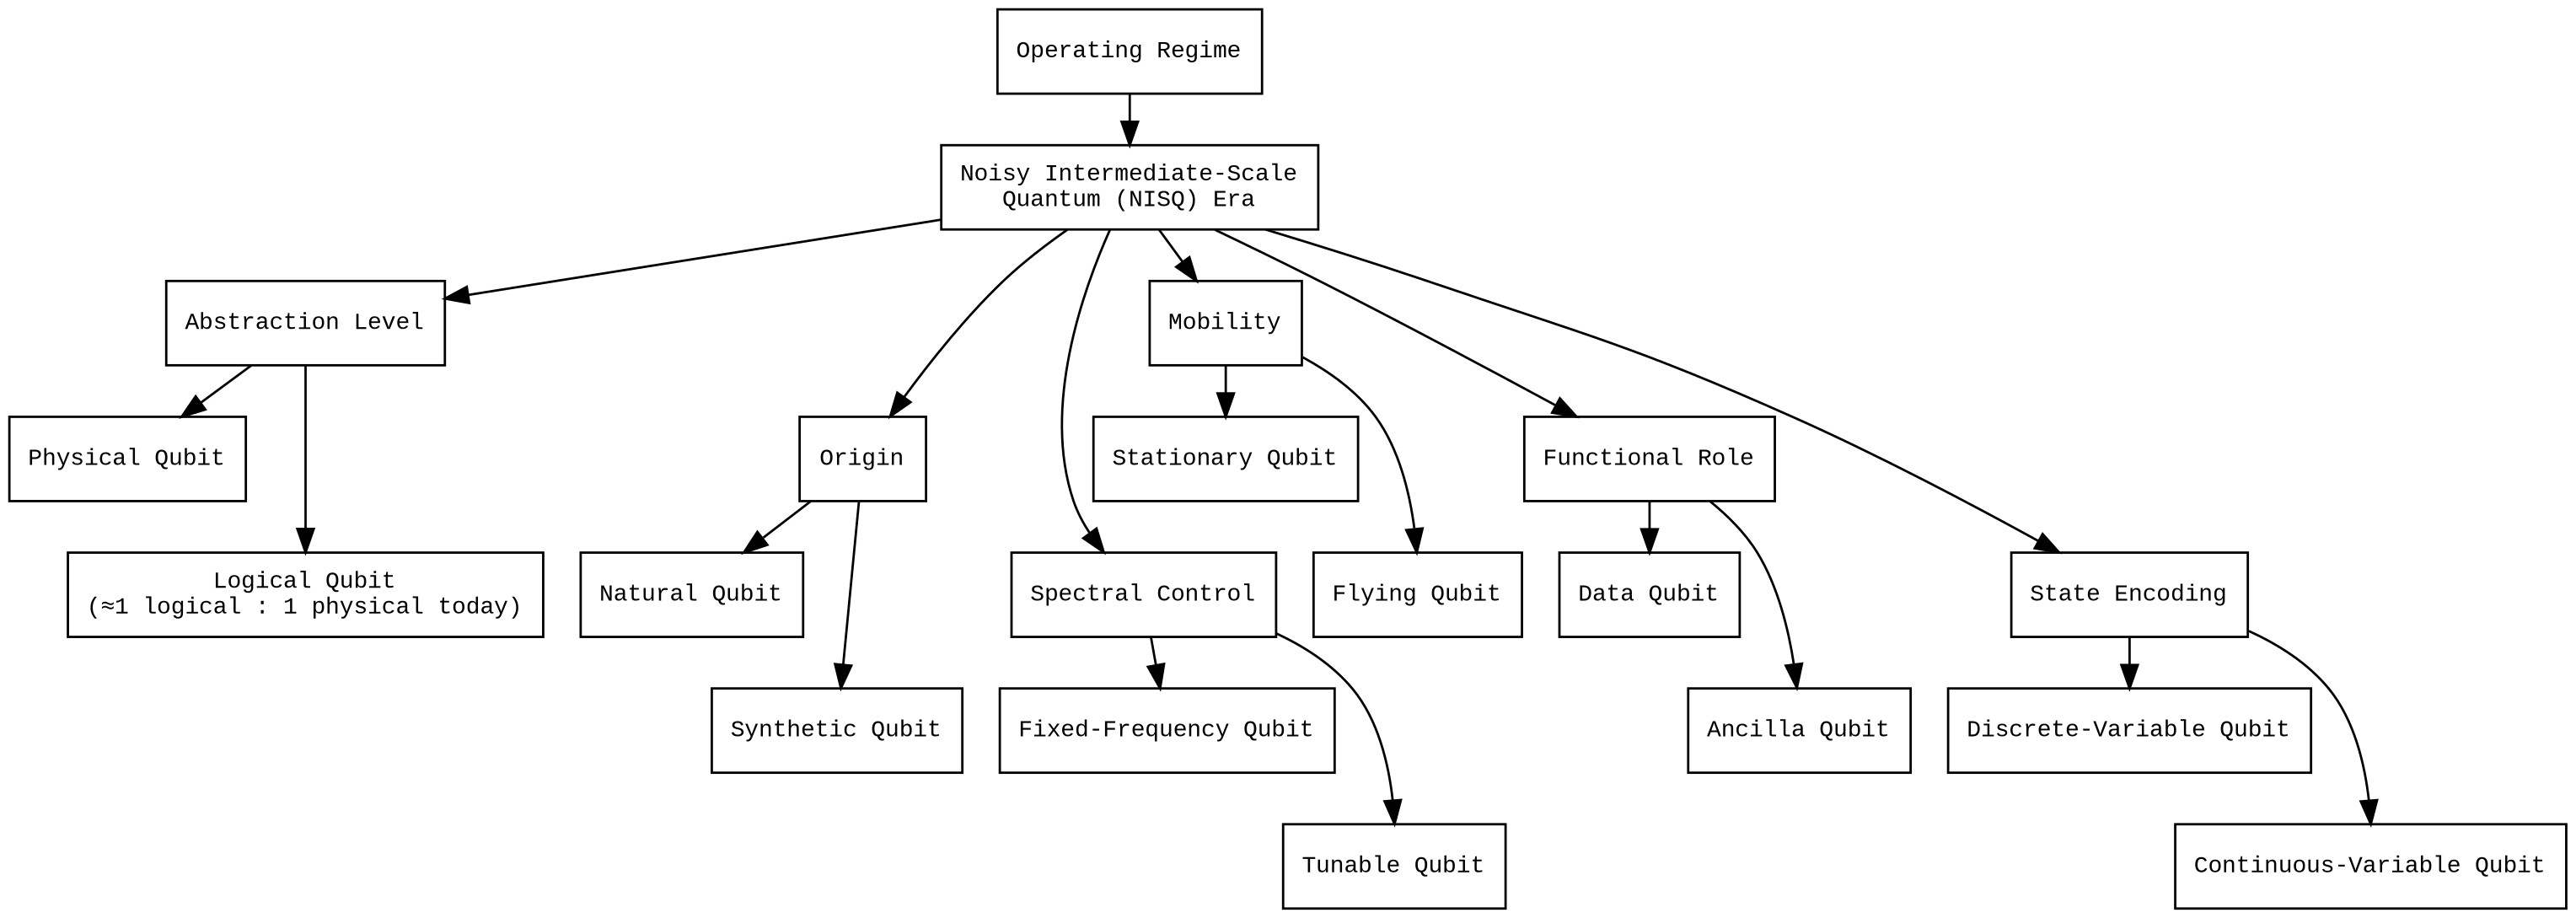

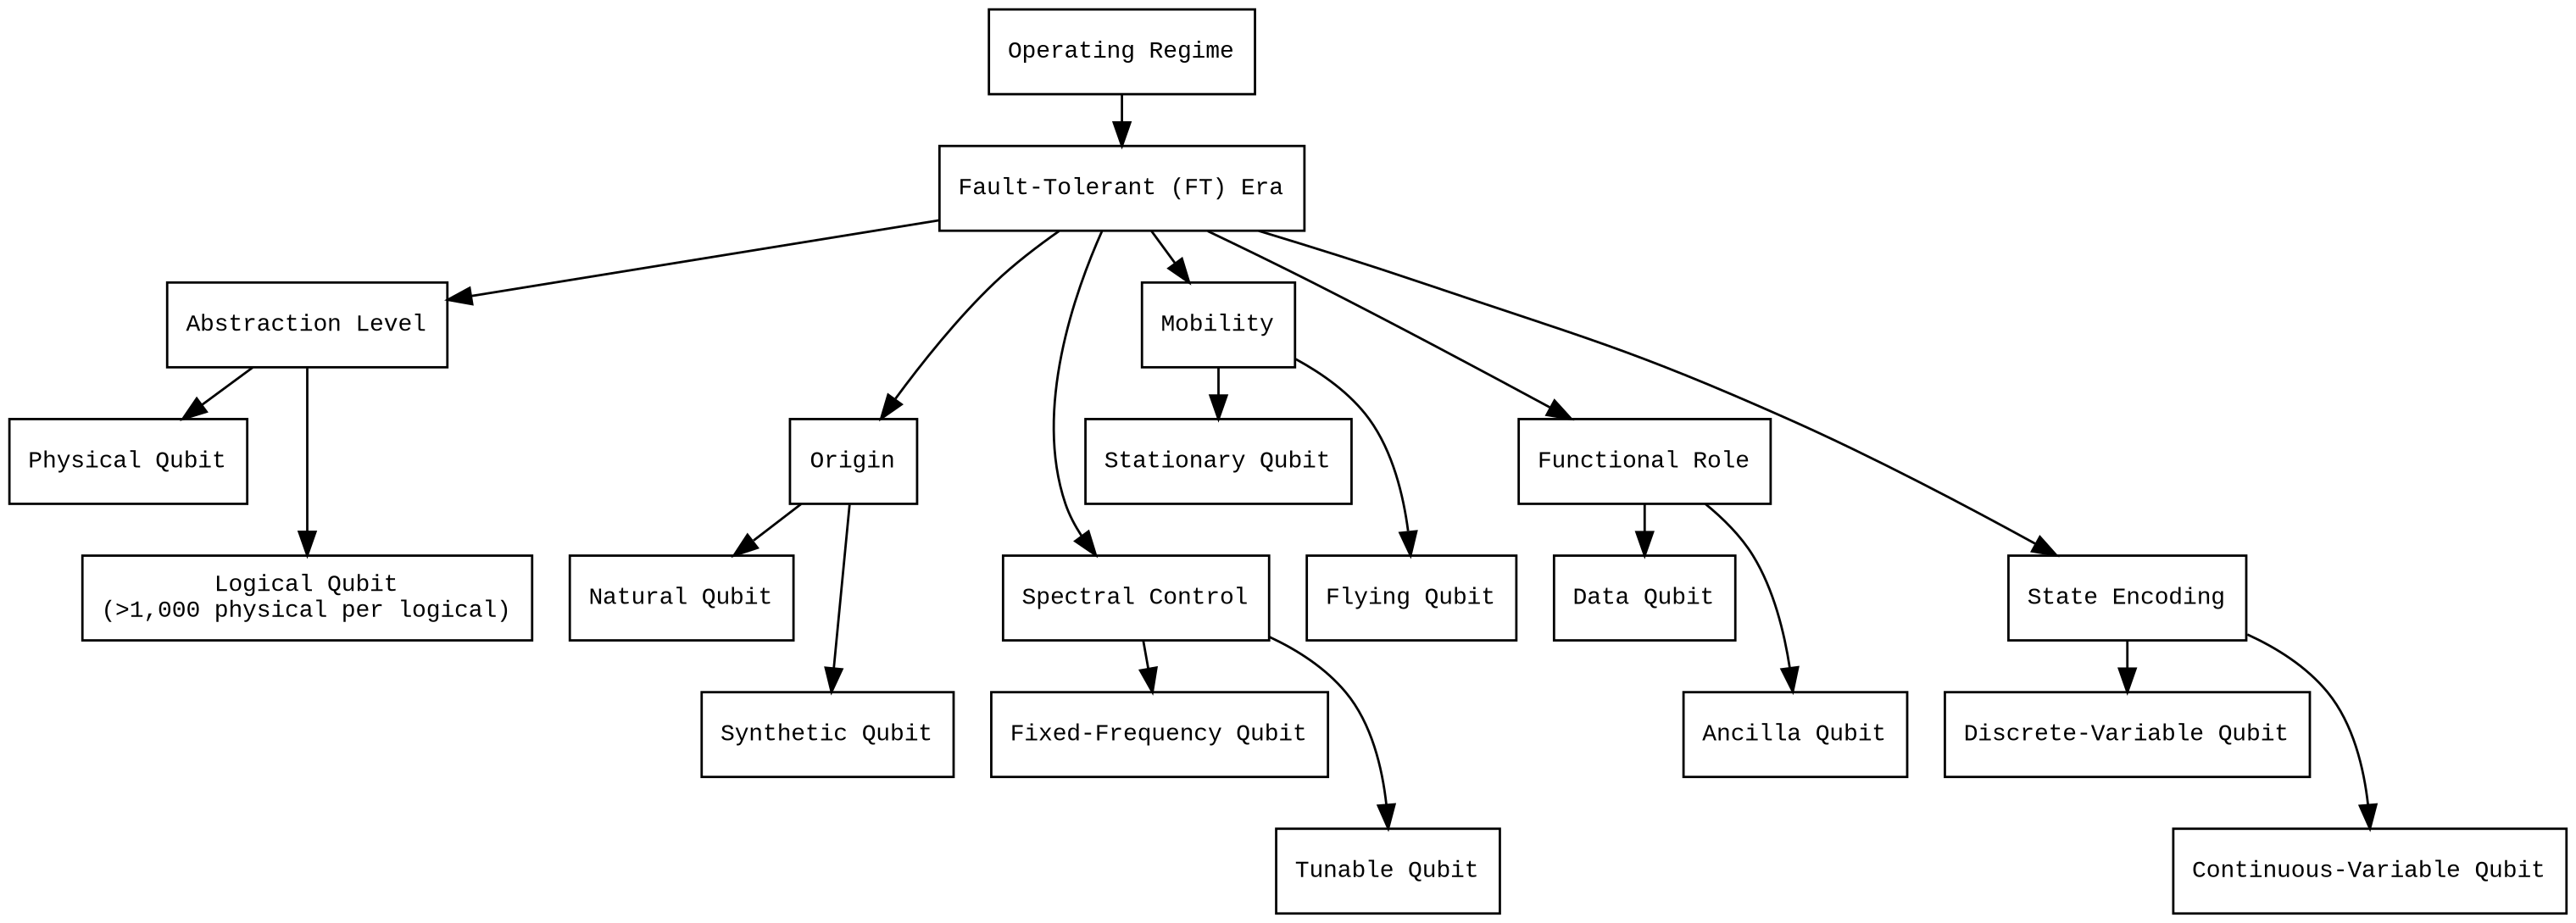

In [5]:
!uv pip install --quiet graphviz matplotlib ipython

"""This script constructs two separate Graphviz diagrams for qubit classification.
"""

import graphviz
from IPython.display import display
from IPython.display import Image
import matplotlib.pyplot as plt

# Global Resolution and Font Defaults
plt.rcParams["figure.dpi"] = 200
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
plt.rcParams["font.weight"] = "normal"

# Control Knobs
GRAPH_DPI = str(plt.rcParams["figure.dpi"])
NODE_FONT = "DejaVu Sans"
EDGE_ROUTING = "spline"
NODE_SHAPE = "box"
BACKGROUND_COLOR = "white"
FOREGROUND_COLOR = "black"
RANK_DIRECTION = "TB"
RANK_SEPARATION = "0.30"
NODE_SEPARATION = "0.22"
STAGGER_STEP = 1
CATEGORY_STAGGER_CYCLE = 3

if __name__ == "__main__":
    # Shared Taxonomic Categories
    shared_categories = [
        (
            "Origin",
            "Origin",
            [
                ("Natural", "Natural Qubit"),
                ("Synthetic", "Synthetic Qubit"),
            ],
        ),
        (
            "Spectral",
            "Spectral Control",
            [
                ("Fixed", "Fixed-Frequency Qubit"),
                ("Tunable", "Tunable Qubit"),
            ],
        ),
        (
            "Mobility",
            "Mobility",
            [
                ("Stationary", "Stationary Qubit"),
                ("Flying", "Flying Qubit"),
            ],
        ),
        (
            "Role",
            "Functional Role",
            [
                ("Data", "Data Qubit"),
                ("Ancilla", "Ancilla Qubit"),
            ],
        ),
        (
            "Encoding",
            "State Encoding",
            [
                ("DV", "Discrete-Variable Qubit"),
                ("CV", "Continuous-Variable Qubit"),
            ],
        ),
    ]

    # Operating Regime Definitions
    era_specifications = [
        (
            "Operating_Regime_NISQ_Era",
            "Noisy Intermediate-Scale\nQuantum (NISQ) Era",
            "Logical Qubit\n(≈1 logical : 1 physical today)",
        ),
        (
            "Operating_Regime_FT_Era",
            "Fault-Tolerant (FT) Era",
            "Logical Qubit\n(>1,000 physical per logical)",
        ),
    ]

    # Diagram Generation and In-Memory Display
    for graph_name, era_label, logical_leaf_label in era_specifications:
        dag = graphviz.Digraph(name=graph_name, format="png")

        dag.attr(
            dpi=GRAPH_DPI,
            splines=EDGE_ROUTING,
            bgcolor=BACKGROUND_COLOR,
            rankdir=RANK_DIRECTION,
            ranksep=RANK_SEPARATION,
            nodesep=NODE_SEPARATION,
        )
        dag.attr(
            "node",
            shape=NODE_SHAPE,
            style="solid",
            color=FOREGROUND_COLOR,
            fontcolor=FOREGROUND_COLOR,
            fontname=NODE_FONT,
            fontsize="10",
        )
        dag.attr(
            "edge",
            color=FOREGROUND_COLOR,
            fontcolor=FOREGROUND_COLOR,
            arrowhead="normal",
            fontname=NODE_FONT,
            fontsize="9",
        )

        # Root Hierarchy
        dag.node("Root", "Operating Regime")
        dag.node("Era", era_label)
        dag.edge("Root", "Era", minlen="1", weight="10")

        # Full Category List for Current Regime
        categories = [
            (
                "Abstraction",
                "Abstraction Level",
                [
                    ("Physical", "Physical Qubit"),
                    ("Logical", logical_leaf_label),
                ],
            ),
        ] + shared_categories

        # Staggered Category and Leaf Nodes
        for cat_idx, (cat_id, cat_label, leaves) in enumerate(categories):
            dag.node(cat_id, cat_label)
            cat_minlen = 1 + (cat_idx % CATEGORY_STAGGER_CYCLE) * STAGGER_STEP
            dag.edge("Era", cat_id, minlen=str(cat_minlen))

            for leaf_idx, (leaf_id, leaf_label) in enumerate(leaves):
                dag.node(leaf_id, leaf_label)
                leaf_minlen = 1 + leaf_idx * STAGGER_STEP
                dag.edge(cat_id, leaf_id, minlen=str(leaf_minlen))

        binary_png = dag.pipe(format="png")
        display(Image(data=binary_png))